# CM2000 Lab 2.A. Pose Estimation

# Pose estimation with MoveNet

This code was adapted from TensowFlow MoveNet tutorial (see License below).

<a target="_blank" href="https://www.tensorflow.org/hub/tutorials/movenet">View on TensorFlow.org</a>

In [2]:
# Copyright 2021 The TensorFlow Hub Authors. All Rights Reserved.
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
# ==============================================================================

**[MoveNet](https://t.co/QpfnVL0YYI?amp=1)** is an ultra fast and accurate model that detects 17 keypoints of a body. The model is offered on [TF Hub](https://tfhub.dev/s?q=movenet) with two variants, known as Lightning and Thunder. Lightning is intended for latency-critical applications, while Thunder is intended for applications that require high accuracy. Both models run faster than real time (30+ FPS) on most modern desktops, laptops, and phones, which proves crucial for live fitness, health, and wellness applications.

This Colab walks you through the details of how to load MoveNet, and run inference on the input image and video below.

Note: check out the [live demo](https://storage.googleapis.com/tfjs-models/demos/pose-detection/index.html?model=movenet) for how the model works!

## Imports

In [3]:
# Install library locally in this notebook kernel
!pip install -q git+https://github.com/tensorflow/docs

In [4]:
# Tip: remember to install all packages in yout virtual env beforehand and activating it on vscode
import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import cv2

# Import matplotlib libraries
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
import matplotlib.patches as patches

# Some modules to display an animation using imageio.
from IPython.display import display

# Tools
from tools import *

/opt/anaconda3/envs/videoLabb/lib/python3.11/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


## Visualization functions

In [5]:
# Tensorflow helper functions for visualization
# Tip: you want to understand this, but you don't want to change it

# Dictionary that maps from joint names to keypoint indices.
KEYPOINT_DICT = {
    'nose': 0,
    'left_eye': 1,
    'right_eye': 2,
    'left_ear': 3,
    'right_ear': 4,
    'left_shoulder': 5,
    'right_shoulder': 6,
    'left_elbow': 7,
    'right_elbow': 8,
    'left_wrist': 9,
    'right_wrist': 10,
    'left_hip': 11,
    'right_hip': 12,
    'left_knee': 13,
    'right_knee': 14,
    'left_ankle': 15,
    'right_ankle': 16
}

# Maps bones to a matplotlib color name.
KEYPOINT_EDGE_INDS_TO_COLOR = {
    (0, 1): 'm',
    (0, 2): 'c',
    (1, 3): 'm',
    (2, 4): 'c',
    (0, 5): 'm',
    (0, 6): 'c',
    (5, 7): 'm',
    (7, 9): 'm',
    (6, 8): 'c',
    (8, 10): 'c',
    (5, 6): 'y',
    (5, 11): 'm',
    (6, 12): 'c',
    (11, 12): 'y',
    (11, 13): 'm',
    (13, 15): 'm',
    (12, 14): 'c',
    (14, 16): 'c'
}

def _keypoints_and_edges_for_display(keypoints_with_scores,
                                     height,
                                     width,
                                     keypoint_threshold=0.11):
    """Returns high confidence keypoints and edges for visualization.

    Args:
      keypoints_with_scores: A numpy array with shape [1, 1, 17, 3] representing
        the keypoint coordinates and scores returned from the MoveNet model.
      height: height of the image in pixels.
      width: width of the image in pixels.
      keypoint_threshold: minimum confidence score for a keypoint to be
        visualized.

    Returns:
      A (keypoints_xy, edges_xy, edge_colors) containing:
        * the coordinates of all keypoints of all detected entities;
        * the coordinates of all skeleton edges of all detected entities;
        * the colors in which the edges should be plotted.
    """
    keypoints_all = []
    keypoint_edges_all = []
    edge_colors = []
    num_instances, _, _, _ = keypoints_with_scores.shape
    for idx in range(num_instances):
        kpts_x = keypoints_with_scores[0, idx, :, 1]
        kpts_y = keypoints_with_scores[0, idx, :, 0]
        kpts_scores = keypoints_with_scores[0, idx, :, 2]
        kpts_absolute_xy = np.stack(
            [width * np.array(kpts_x), height * np.array(kpts_y)], axis=-1)
        kpts_above_thresh_absolute = kpts_absolute_xy[
            kpts_scores > keypoint_threshold, :]
        keypoints_all.append(kpts_above_thresh_absolute)

        for edge_pair, color in KEYPOINT_EDGE_INDS_TO_COLOR.items():
            if (kpts_scores[edge_pair[0]] > keypoint_threshold and
                    kpts_scores[edge_pair[1]] > keypoint_threshold):
                x_start = kpts_absolute_xy[edge_pair[0], 0]
                y_start = kpts_absolute_xy[edge_pair[0], 1]
                x_end = kpts_absolute_xy[edge_pair[1], 0]
                y_end = kpts_absolute_xy[edge_pair[1], 1]
                line_seg = np.array([[x_start, y_start], [x_end, y_end]])
                keypoint_edges_all.append(line_seg)
                edge_colors.append(color)
    if keypoints_all:
        keypoints_xy = np.concatenate(keypoints_all, axis=0)
    else:
        keypoints_xy = np.zeros((0, 17, 2))

    if keypoint_edges_all:
        edges_xy = np.stack(keypoint_edges_all, axis=0)
    else:
        edges_xy = np.zeros((0, 2, 2))
    return keypoints_xy, edges_xy, edge_colors


def draw_prediction_on_image(
        image, keypoints_with_scores, crop_region=None, close_figure=False,
        output_image_height=None):
    """Draws the keypoint predictions on image.

    Args:
      image: A numpy array with shape [height, width, channel] representing the
        pixel values of the input image.
      keypoints_with_scores: A numpy array with shape [1, 1, 17, 3] representing
        the keypoint coordinates and scores returned from the MoveNet model.
      crop_region: A dictionary that defines the coordinates of the bounding box
        of the crop region in normalized coordinates (see the init_crop_region
        function below for more detail). If provided, this function will also
        draw the bounding box on the image.
      output_image_height: An integer indicating the height of the output image.
        Note that the image aspect ratio will be the same as the input image.

    Returns:
      A numpy array with shape [out_height, out_width, channel] representing the
      image overlaid with keypoint predictions.
    """
    height, width, channel = image.shape
    aspect_ratio = float(width) / height
    fig, ax = plt.subplots(figsize=(12 * aspect_ratio, 12))
    # To remove the huge white borders
    fig.tight_layout(pad=0)
    ax.margins(0)
    ax.set_yticklabels([])
    ax.set_xticklabels([])
    plt.axis('off')

    im = ax.imshow(image)
    line_segments = LineCollection([], linewidths=(4), linestyle='solid')
    ax.add_collection(line_segments)
    # Turn off tick labels
    scat = ax.scatter([], [], s=60, color='#FF1493', zorder=3)

    (keypoint_locs, keypoint_edges,
     edge_colors) = _keypoints_and_edges_for_display(
         keypoints_with_scores, height, width)

    line_segments.set_segments(keypoint_edges)
    line_segments.set_color(edge_colors)
    if keypoint_edges.shape[0]:
        line_segments.set_segments(keypoint_edges)
        line_segments.set_color(edge_colors)
    if keypoint_locs.shape[0]:
        scat.set_offsets(keypoint_locs)

    if crop_region is not None:
        xmin = max(crop_region['x_min'] * width, 0.0)
        ymin = max(crop_region['y_min'] * height, 0.0)
        rec_width = min(crop_region['x_max'], 0.99) * width - xmin
        rec_height = min(crop_region['y_max'], 0.99) * height - ymin
        rect = patches.Rectangle(
            (xmin, ymin), rec_width, rec_height,
            linewidth=1, edgecolor='b', facecolor='none')
        ax.add_patch(rect)

    fig.canvas.draw()
    image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
    image_from_plot = image_from_plot.reshape(
        fig.canvas.get_width_height()[::-1] + (3,))
    plt.close(fig)
    if output_image_height is not None:
        output_image_width = int(output_image_height / height * width)
        image_from_plot = cv2.resize(
            image_from_plot, dsize=(output_image_width, output_image_height),
            interpolation=cv2.INTER_CUBIC)
    return image_from_plot

## Load Model from TF hub

You can choose to work with one version or try different ones and see which one gives you the best result for the fastest speed. It is not required to change the model. Make sure you are working on your GPU before running this part.

In [6]:
# Here you pick the model, you can try different ones ans see if the result is the same
model_name = "movenet_thunder" #@param ["movenet_lightning", "movenet_thunder", "movenet_lightning_f16.tflite", "movenet_thunder_f16.tflite", "movenet_lightning_int8.tflite", "movenet_thunder_int8.tflite"]

if "tflite" in model_name:
  if "movenet_lightning_f16" in model_name:
    !wget -q -O model.tflite https://tfhub.dev/google/lite-model/movenet/singlepose/lightning/tflite/float16/4?lite-format=tflite
    input_size = 192
  elif "movenet_thunder_f16" in model_name:
    !wget -q -O model.tflite https://tfhub.dev/google/lite-model/movenet/singlepose/thunder/tflite/float16/4?lite-format=tflite
    input_size = 256
  elif "movenet_lightning_int8" in model_name:
    !wget -q -O model.tflite https://tfhub.dev/google/lite-model/movenet/singlepose/lightning/tflite/int8/4?lite-format=tflite
    input_size = 192
  elif "movenet_thunder_int8" in model_name:
    !wget -q -O model.tflite https://tfhub.dev/google/lite-model/movenet/singlepose/thunder/tflite/int8/4?lite-format=tflite
    input_size = 256
  else:
    raise ValueError("Unsupported model name: %s" % model_name)

  # Initialize the TFLite interpreter
  interpreter = tf.lite.Interpreter(model_path="model.tflite")
  interpreter.allocate_tensors()

  def movenet(input_image):
    """Runs detection on an input image.

    Args:
      input_image: A [1, height, width, 3] tensor represents the input image
        pixels. Note that the height/width should already be resized and match the
        expected input resolution of the model before passing into this function.

    Returns:
      A [1, 1, 17, 3] float numpy array representing the predicted keypoint
      coordinates and scores.
    """
    # TF Lite format expects tensor type of uint8.
    input_image = tf.cast(input_image, dtype=tf.uint8)
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    interpreter.set_tensor(input_details[0]['index'], input_image.numpy())
    # Invoke inference.
    interpreter.invoke()
    # Get the model prediction.
    keypoints_with_scores = interpreter.get_tensor(output_details[0]['index'])
    return keypoints_with_scores

else:
  if "movenet_lightning" in model_name:
    module = hub.load("https://tfhub.dev/google/movenet/singlepose/lightning/4")
    input_size = 192
  elif "movenet_thunder" in model_name:
    module = hub.load("https://tfhub.dev/google/movenet/singlepose/thunder/4")
    input_size = 256
  else:
    raise ValueError("Unsupported model name: %s" % model_name)

  def movenet(input_image):
    """Runs detection on an input image.

    Args:
      input_image: A [1, height, width, 3] tensor represents the input image
        pixels. Note that the height/width should already be resized and match the
        expected input resolution of the model before passing into this function.

    Returns:
      A [1, 1, 17, 3] float numpy array representing the predicted keypoint
      coordinates and scores.
    """
    model = module.signatures['serving_default']

    # SavedModel format expects tensor type of int32.
    input_image = tf.cast(input_image, dtype=tf.int32)
    # Run model inference.
    outputs = model(input_image)
    # Output is a [1, 1, 17, 3] tensor.
    keypoints_with_scores = outputs['output_0'].numpy()
    return keypoints_with_scores

## Single Image Example

This session demonstrates the minumum working example of running the model on a **single image** to predict the 17 human keypoints.

### Load Input Image

In [7]:
# Choose image file
image_path = './skeleton_tracking/running_2.jpeg'

In [8]:
# Load the input image.
image = tf.io.read_file(image_path)
image = tf.image.decode_jpeg(image)

### Run Inference

/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)


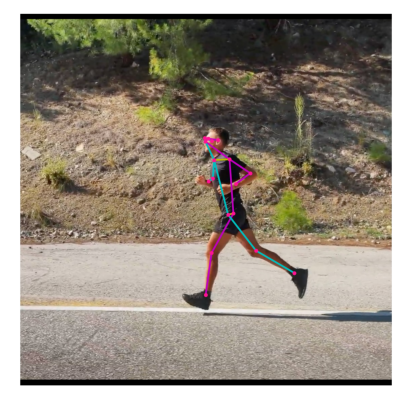

In [9]:
# Resize and pad the image to keep the aspect ratio and fit the expected size.
input_image = tf.expand_dims(image, axis=0)
input_image = tf.image.resize_with_pad(input_image, input_size, input_size)

# Run model inference.
keypoints_with_scores = movenet(input_image)

# Visualize the predictions with image.
display_image = tf.expand_dims(image, axis=0)
display_image = tf.cast(tf.image.resize_with_pad(
    display_image, 1280, 1280), dtype=tf.int32)
output_overlay = draw_prediction_on_image(
    np.squeeze(display_image.numpy(), axis=0), keypoints_with_scores)

plt.figure(figsize=(5, 5))
plt.imshow(output_overlay)
_ = plt.axis('off')

## Task 1: Video (image sequence) skeleton tracking


### 1.1: Code assignment

Run skeleton tracking for a .mp4 file. Use running_2.mp4 as an example. Get familiar with the code and understand the helping functions.

In [10]:
# Tensorflow cropping algorithm
# This section demonstrates how to apply intelligent cropping based on detections from the previous frame when the input is a sequence of frames.
# This allows the model to devote its attention and resources to the main subject, resulting in much better prediction quality without sacrificing the speed.
# Tip: you don't want to change this

# Confidence score to determine whether a keypoint prediction is reliable.
MIN_CROP_KEYPOINT_SCORE = 0.2


def init_crop_region(image_height, image_width):
    """Defines the default crop region.

    The function provides the initial crop region (pads the full image from both
    sides to make it a square image) when the algorithm cannot reliably determine
    the crop region from the previous frame.
    """
    if image_width > image_height:
        box_height = image_width / image_height
        box_width = 1.0
        y_min = (image_height / 2 - image_width / 2) / image_height
        x_min = 0.0
    else:
        box_height = 1.0
        box_width = image_height / image_width
        y_min = 0.0
        x_min = (image_width / 2 - image_height / 2) / image_width

    return {
        'y_min': y_min,
        'x_min': x_min,
        'y_max': y_min + box_height,
        'x_max': x_min + box_width,
        'height': box_height,
        'width': box_width
    }


def torso_visible(keypoints):
    """Checks whether there are enough torso keypoints.

    This function checks whether the model is confident at predicting one of the
    shoulders/hips which is required to determine a good crop region.
    """
    return ((keypoints[0, 0, KEYPOINT_DICT['left_hip'], 2] >
             MIN_CROP_KEYPOINT_SCORE or
            keypoints[0, 0, KEYPOINT_DICT['right_hip'], 2] >
             MIN_CROP_KEYPOINT_SCORE) and
            (keypoints[0, 0, KEYPOINT_DICT['left_shoulder'], 2] >
             MIN_CROP_KEYPOINT_SCORE or
            keypoints[0, 0, KEYPOINT_DICT['right_shoulder'], 2] >
             MIN_CROP_KEYPOINT_SCORE))


def determine_torso_and_body_range(
        keypoints, target_keypoints, center_y, center_x):
    """Calculates the maximum distance from each keypoints to the center location.

    The function returns the maximum distances from the two sets of keypoints:
    full 17 keypoints and 4 torso keypoints. The returned information will be
    used to determine the crop size. See determineCropRegion for more detail.
    """
    torso_joints = ['left_shoulder', 'right_shoulder', 'left_hip', 'right_hip']
    max_torso_yrange = 0.0
    max_torso_xrange = 0.0
    for joint in torso_joints:
        dist_y = abs(center_y - target_keypoints[joint][0])
        dist_x = abs(center_x - target_keypoints[joint][1])
        if dist_y > max_torso_yrange:
            max_torso_yrange = dist_y
        if dist_x > max_torso_xrange:
            max_torso_xrange = dist_x

    max_body_yrange = 0.0
    max_body_xrange = 0.0
    for joint in KEYPOINT_DICT.keys():
        if keypoints[0, 0, KEYPOINT_DICT[joint], 2] < MIN_CROP_KEYPOINT_SCORE:
            continue
        dist_y = abs(center_y - target_keypoints[joint][0])
        dist_x = abs(center_x - target_keypoints[joint][1])
        if dist_y > max_body_yrange:
            max_body_yrange = dist_y

        if dist_x > max_body_xrange:
            max_body_xrange = dist_x

    return [max_torso_yrange, max_torso_xrange, max_body_yrange, max_body_xrange]


def determine_crop_region(
        keypoints, image_height,
        image_width):
    """Determines the region to crop the image for the model to run inference on.

    The algorithm uses the detected joints from the previous frame to estimate
    the square region that encloses the full body of the target person and
    centers at the midpoint of two hip joints. The crop size is determined by
    the distances between each joints and the center point.
    When the model is not confident with the four torso joint predictions, the
    function returns a default crop which is the full image padded to square.
    """
    target_keypoints = {}
    for joint in KEYPOINT_DICT.keys():
        target_keypoints[joint] = [
            keypoints[0, 0, KEYPOINT_DICT[joint], 0] * image_height,
            keypoints[0, 0, KEYPOINT_DICT[joint], 1] * image_width
        ]

    if torso_visible(keypoints):
        center_y = (target_keypoints['left_hip'][0] +
                    target_keypoints['right_hip'][0]) / 2
        center_x = (target_keypoints['left_hip'][1] +
                    target_keypoints['right_hip'][1]) / 2

        (max_torso_yrange, max_torso_xrange,
         max_body_yrange, max_body_xrange) = determine_torso_and_body_range(
            keypoints, target_keypoints, center_y, center_x)

        crop_length_half = np.amax(
            [max_torso_xrange * 1.9, max_torso_yrange * 1.9,
             max_body_yrange * 1.2, max_body_xrange * 1.2])

        tmp = np.array(
            [center_x, image_width - center_x, center_y, image_height - center_y])
        crop_length_half = np.amin(
            [crop_length_half, np.amax(tmp)])

        crop_corner = [center_y - crop_length_half,
                       center_x - crop_length_half]

        if crop_length_half > max(image_width, image_height) / 2:
            return init_crop_region(image_height, image_width)
        else:
            crop_length = crop_length_half * 2
            return {
                'y_min': crop_corner[0] / image_height,
                'x_min': crop_corner[1] / image_width,
                'y_max': (crop_corner[0] + crop_length) / image_height,
                'x_max': (crop_corner[1] + crop_length) / image_width,
                'height': (crop_corner[0] + crop_length) / image_height -
                crop_corner[0] / image_height,
                'width': (crop_corner[1] + crop_length) / image_width -
                crop_corner[1] / image_width
            }
    else:
        return init_crop_region(image_height, image_width)


def crop_and_resize(image, crop_region, crop_size):
    """Crops and resize the image to prepare for the model input."""
    boxes = [[crop_region['y_min'], crop_region['x_min'],
              crop_region['y_max'], crop_region['x_max']]]
    output_image = tf.image.crop_and_resize(
        image, box_indices=[0], boxes=boxes, crop_size=crop_size)
    return output_image



In [11]:
# Tensorflow inference algorithm
# Tip: you want to understand what is happening here

def run_inference(movenet, image, crop_region, crop_size):
    """Runs model inferece on the cropped region.

    The function runs the model inference on the cropped region and updates the
    model output to the original image coordinate system.
    """
    image_height, image_width, _ = image.shape
    input_image = crop_and_resize(
        tf.expand_dims(image, axis=0), crop_region, crop_size=crop_size)
    # Run model inference.
    # Tip: understand this output format to extract joints.
    keypoints_with_scores = movenet(input_image)
    # Update the coordinates.
    for idx in range(17):
        keypoints_with_scores[0, 0, idx, 0] = (
            crop_region['y_min'] * image_height +
            crop_region['height'] * image_height *
            keypoints_with_scores[0, 0, idx, 0]) / image_height
        keypoints_with_scores[0, 0, idx, 1] = (
            crop_region['x_min'] * image_width +
            crop_region['width'] * image_width *
            keypoints_with_scores[0, 0, idx, 1]) / image_width
    return keypoints_with_scores

#### Convert video to gif

The .gif file is an image sequence. You can also read directly .mp4 formats and store the frames as arrays, skipping the .gif conversion.
We will convert to .gif just for visualization.

In [12]:
# Load the MP4 video and convert to gif
video_file = './skeleton_tracking/running_2.mp4'
mp4_to_gif(video_file)

Conversion of ./skeleton_tracking/running_2.mp4 complete.


#### Load Input Image Sequence (array or .gif)

In [13]:
# Choose gif file
gif_path = './skeleton_tracking/running_2.gif'

In [14]:
# Load the input image sequence.
image = tf.io.read_file(gif_path)
image = tf.image.decode_gif(image)

In [15]:
# Get the frame rate of the video
cap = cv2.VideoCapture(video_file)
frame_rate = int(cap.get(cv2.CAP_PROP_FPS))

#### Run Inference with Cropping Algorithm

In [16]:
# Load the input image.
num_frames, image_height, image_width, _ = image.shape
crop_region = init_crop_region(image_height, image_width)

output_images = []
positions, confidences = [], []
bar = display(progress(0, num_frames-1), display_id=True)
for frame_idx in range(num_frames):
    keypoints_with_scores = run_inference(
        movenet, image[frame_idx, :, :, :], crop_region,
        crop_size=[input_size, input_size])
    output_images.append(draw_prediction_on_image(
        image[frame_idx, :, :, :].numpy().astype(np.int32),
        keypoints_with_scores, crop_region=None,
        close_figure=True, output_image_height=300))
    crop_region = determine_crop_region(
        keypoints_with_scores, image_height, image_width)
    bar.update(progress(frame_idx, num_frames-1))


/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: Matplotl

In [17]:

# Prepare gif visualization.
output = np.stack(output_images, axis=0)
filename = gif_path[:-4]+'_skeleton.gif'
# Tip: you can play around with duration to make it slowmo
to_gif(output, duration=int(1000/frame_rate), filename=filename)

./skeleton_tracking/running_2_skeleton.gif saved!


#### Visualize each frame with predictions

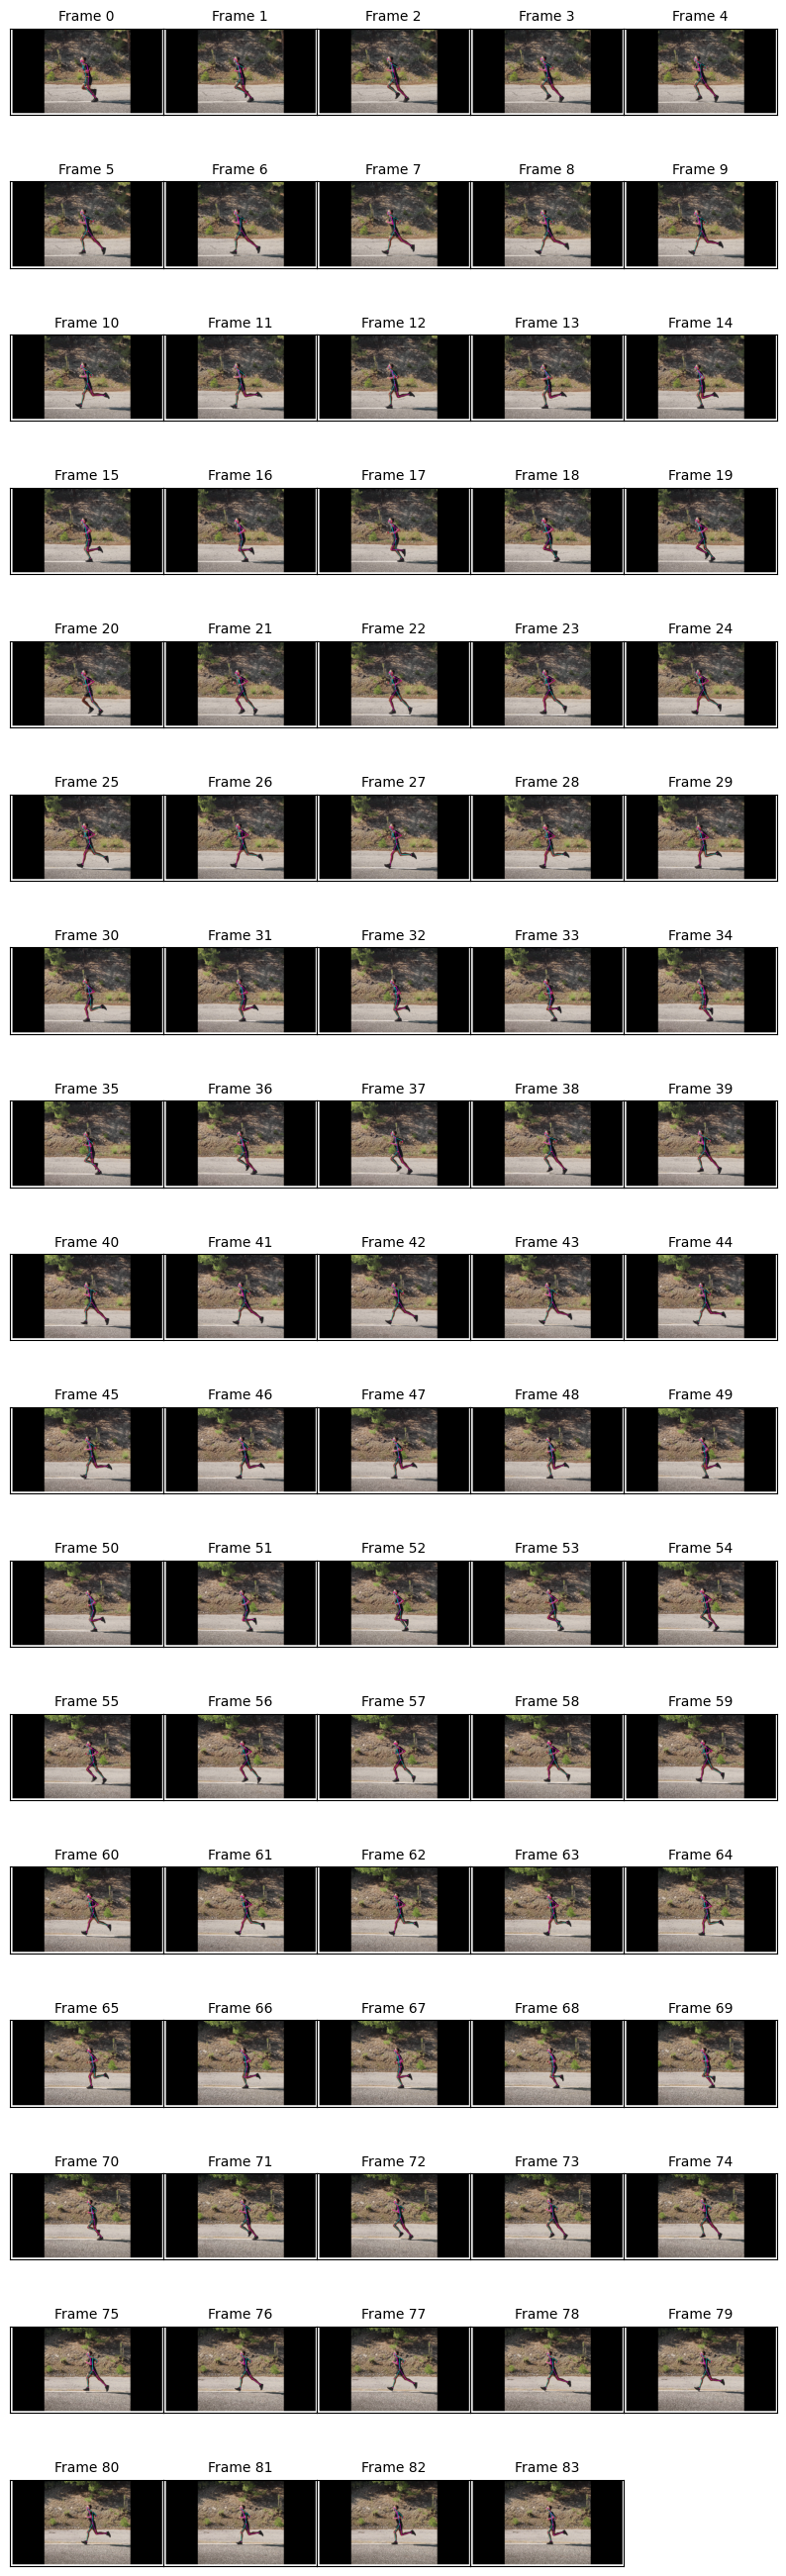

In [18]:
# Prepare gif visualization.
output = np.stack(output_images, axis=0)
filename = gif_path.split(".")[0]+'_skeleton'
# Tip: you can play around with duration to make it slowmo
to_img_sequence(output, filename, cols=5)

## Task 2: Joint coordinates


### 2.1. Code assignment

Change the code to retrieve the joint coordinates and confidence scores. Plot joint coordinates of hip, knee and ankle of right and left sides together with confidence scores of the predictions.

Copy the code from section "Run Inference with Cropping Algorithm", paste below and make the relevant changes to complete the task.  
Tip: to retrieve the coordinates, one possible approach is to rewrite your own version of the function _keypoints_and_edges_for_display and call it when you run the inference for each frame.

Example of coordinates plot of the knee joint. Do not consider those values.

![Joint coordinates plot example](example_plots/knee_coordinates.png)

/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use buffer_rgba instead.
  image_from_plot = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)
/var/folders/7n/w4n4h6cn1zs6n4k4dbv1f3v40000gn/T/ipykernel_42448/475605926.py:163: Matplotl

(84, 17, 2) (84, 17)


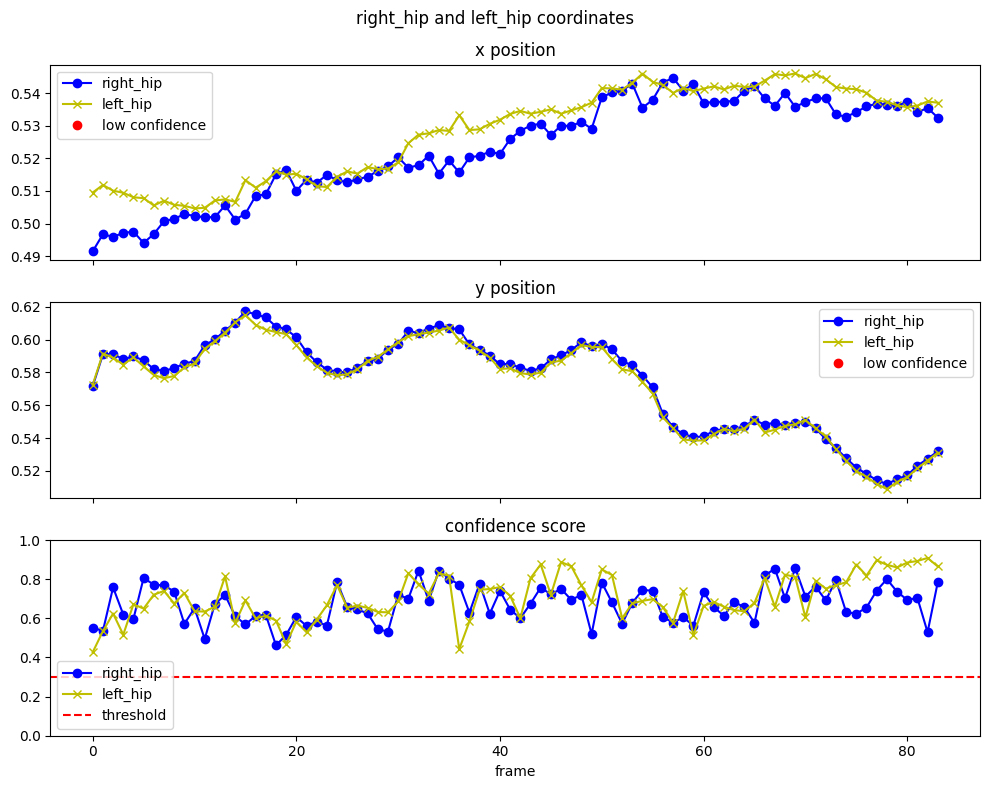

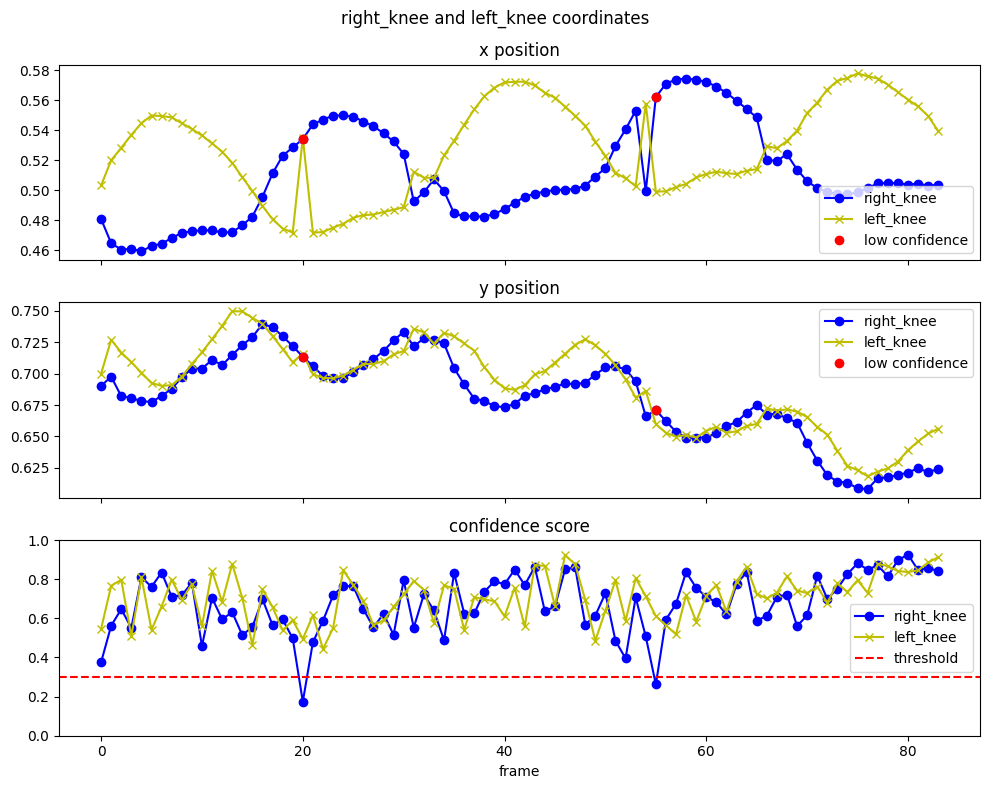

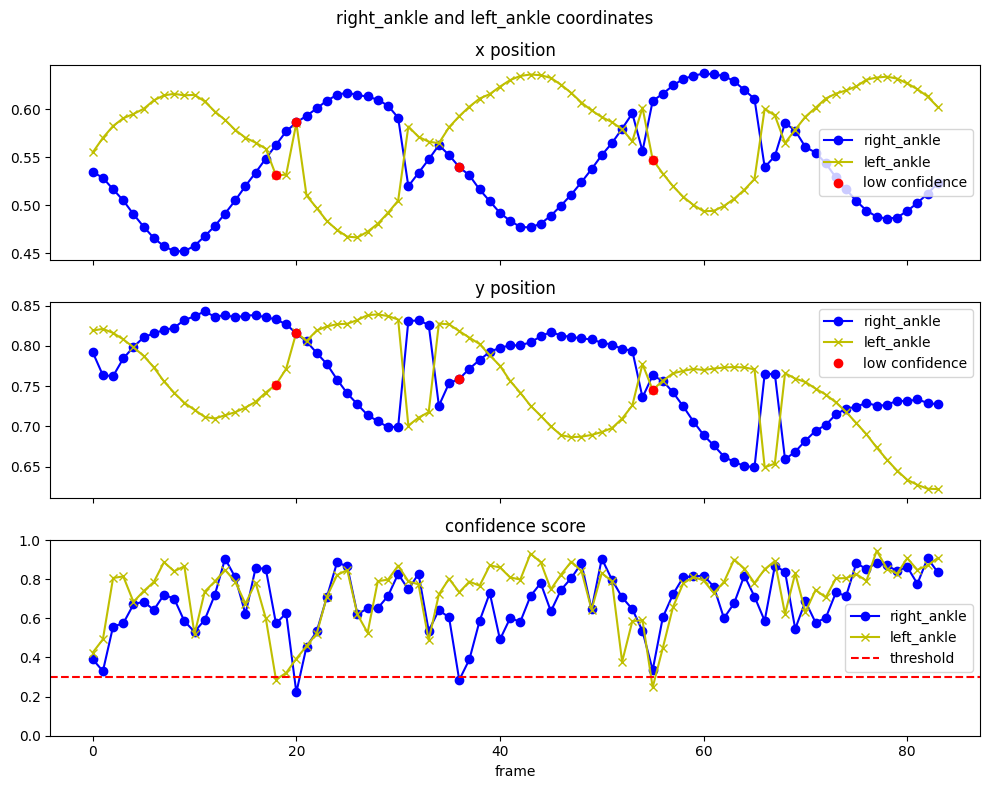

In [19]:
# NEW:
def get_keypoints(keypoints_with_scores):
    kpts = keypoints_with_scores[0, 0, :, :]
    xy = kpts[:, [1, 0]]
    scores = kpts[:, 2]
    return xy, scores

# Load the input image.
num_frames, image_height, image_width, _ = image.shape
crop_region = init_crop_region(image_height, image_width)

output_images = []
positions, confidences = [], []
bar = display(progress(0, num_frames-1), display_id=True)
for frame_idx in range(num_frames):
    keypoints_with_scores = run_inference(
        movenet, image[frame_idx, :, :, :], crop_region,
        crop_size=[input_size, input_size])
    # NEW:
    xy, scores = get_keypoints(keypoints_with_scores)
    positions.append(xy)
    confidences.append(scores)

    output_images.append(draw_prediction_on_image(
        image[frame_idx, :, :, :].numpy().astype(np.int32),
        keypoints_with_scores, crop_region=None,
        close_figure=True, output_image_height=300))
    crop_region = determine_crop_region(
        keypoints_with_scores, image_height, image_width)
    bar.update(progress(frame_idx, num_frames-1))

# NEW:
positions = np.array(positions)
confidences = np.array(confidences)
print(positions.shape, confidences.shape)

# NEW:
THRESHOLD = 0.3
frames = np.arange(num_frames)

for joint in ['hip', 'knee', 'ankle']:
    r = KEYPOINT_DICT['right_' + joint]
    l = KEYPOINT_DICT['left_' + joint]
    low_r = confidences[:, r] < THRESHOLD
    low_l = confidences[:, l] < THRESHOLD

    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

    for row, title in enumerate(['x position', 'y position']):
        ax = axes[row]
        ax.plot(frames, positions[:, r, row], 'bo-', label='right_' + joint)
        ax.plot(frames, positions[:, l, row], 'yx-', label='left_' + joint)
        
        ax.plot(frames[low_r], positions[low_r, r, row], 'ro', label='low confidence')
        ax.plot(frames[low_l], positions[low_l, l, row], 'ro')
        ax.set_title(title)
        ax.legend()

    
    axes[2].plot(frames, confidences[:, r], 'bo-', label='right_' + joint)
    axes[2].plot(frames, confidences[:, l], 'yx-', label='left_' + joint)
    axes[2].axhline(THRESHOLD, color='r', linestyle='--', label='threshold')
    axes[2].set_ylim(0, 1)
    axes[2].set_title('confidence score')
    axes[2].set_xlabel('frame')
    axes[2].legend()

    fig.suptitle(f'right_{joint} and left_{joint} coordinates')
    plt.tight_layout()
    plt.show()

### 2.2. Written assignment

Analyse the correctness of the predictions and the confidence scores. Try to change the keypoint_threshold threshold at _keypoints_and_edges_for_display. Can you use the confidence scores to identify wrong predictions? Write down your reflections and conclusions.

The hips are predicted well: the left and right curves are smooth, almost identical in y, and the confidence never drops below the threshold. The knees look good in y but have a few short left/right swaps in x. The ankles are the least reliable, with several swaps where the curves suddenly trade places for one to three frames, mostly when one foot passes behind the other. The confidence often drops around these errors, but not consistently. With a threshold of 0.6, many correct ankle predictions were flagged, while some swaps still had high confidence. Changing keypoint_threshold showed the same trade-off, a higher value hides more wrong joints but also correct ones. Confidence scores can therefore warn about uncertain frames, but they can't reliably identify wrong predictions, especially left/right swaps.

## Task 3: Knee angles


### 3.1. Code assignment


Compute and plot the knee angles (right and left) on 2D (sagittal) plane.

Write your own functions below.  
Tip: compute a vector for the upper leg and a vector for the lower leg, and use them to find the knee angle.

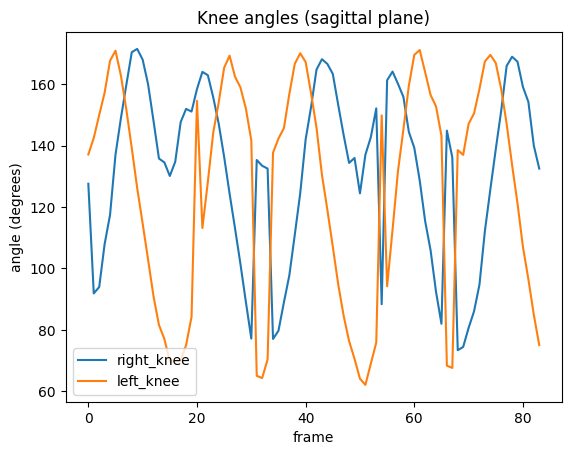

In [20]:
def get_angle(hip, knee, ankle):
    thigh = hip - knee
    shin = ankle - knee
    cos_angle = np.dot(thigh, shin) / (np.linalg.norm(thigh) * np.linalg.norm(shin))
    return np.degrees(np.arccos(cos_angle))

pixels = positions * [image_width, image_height]

for side in ['right', 'left']:
    angles = []
    for frame in pixels:
        angles.append(get_angle(frame[KEYPOINT_DICT[side + '_hip']],
                                frame[KEYPOINT_DICT[side + '_knee']],
                                frame[KEYPOINT_DICT[side + '_ankle']]))
    plt.plot(angles, label=side + '_knee')

plt.title('Knee angles (sagittal plane)')
plt.xlabel('frame')
plt.ylabel('angle (degrees)')
plt.legend()
plt.show()

### 3.2. Written assignment


Analyze and discuss the results, limitations and sources of error. Then, write about how it could be used to improve technique in this or other sports. 

The knee angles show a clear running pattern, with each knee going from about 170 to 70 (degrees) and the legs alternating. The sudden jumps around frames 20, 32, 54 and 67 are errors where the model mixed up the left and right legs. Since the angles are measured in 2D, they're only accurate if the runner moves straight across the camera. Still, the method only needs a normal video, so it could help coaches check knee bend or differences between the legs, in running or in other sports like squats or jumping.

# Pose estimation with YOLO

## Imports

In [21]:
import ultralytics
ultralytics.checks()
import cv2
from ultralytics import YOLO

Ultralytics 8.3.197 🚀 Python-3.11.9 torch-2.8.0 CPU (Apple M2)
Setup complete ✅ (8 CPUs, 8.0 GB RAM, 199.1/460.4 GB disk)


## Video tracking example

In [22]:
# Load the YOLOv8 model
model = YOLO('yolov8n-pose.pt')

# Open the video file
video_path = "skeleton_tracking/running_2.mp4"
cap = cv2.VideoCapture(video_path)

# Loop through the video frames
while cap.isOpened():
    # Read a frame from the video
    success, frame = cap.read()

    if not success:
        break

    # Run YOLOv8 tracking on the frame, persisting tracks between frames
    results = model.track(frame, persist=True, tracker ='bytetrack.yaml', conf=0.05, classes=0)

    # Visualize the results on the frame
    annotated_frame = results[0].plot()

    # Display the annotated frame
    cv2.imshow("YOLOv8 Tracking", annotated_frame)

    # Break the loop if 'q' is pressed
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

# Release the video capture object and close windows
cv2.waitKey(0)
cv2.destroyWindow("YOLOv8 Tracking")
cv2.waitKey(1)
cap.release()


0: 384x640 1 person, 65.6ms
Speed: 5.3ms preprocess, 65.6ms inference, 7.1ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 44.0ms
Speed: 1.9ms preprocess, 44.0ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 40.9ms
Speed: 1.3ms preprocess, 40.9ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 38.7ms
Speed: 1.3ms preprocess, 38.7ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 44.3ms
Speed: 1.2ms preprocess, 44.3ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 34.7ms
Speed: 1.4ms preprocess, 34.7ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 33.1ms
Speed: 1.2ms preprocess, 33.1ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 32.8ms
Speed: 1.4ms preprocess, 32.8ms inference, 0.4ms postprocess per image at shape (1, 3, 38

## Task 4: Joint coordinates with YOLO

### 4.1. Code assignment

Change the code above to retrieve the joint coordinates. Plot joint coordinates of hip, knee and ankle of right and left sides.

Copy the code from above, paste below and make the relevant changes to complete the task.  


0: 384x640 1 person, 38.7ms
Speed: 1.2ms preprocess, 38.7ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 36.4ms
Speed: 1.5ms preprocess, 36.4ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 36.7ms
Speed: 1.2ms preprocess, 36.7ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 41.2ms
Speed: 1.2ms preprocess, 41.2ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 39.4ms
Speed: 1.3ms preprocess, 39.4ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 35.2ms
Speed: 1.2ms preprocess, 35.2ms inference, 0.5ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 36.7ms
Speed: 1.9ms preprocess, 36.7ms inference, 0.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 35.7ms
Speed: 1.3ms preprocess, 35.7ms inference, 0.4ms postprocess per image at shape (1, 3, 38

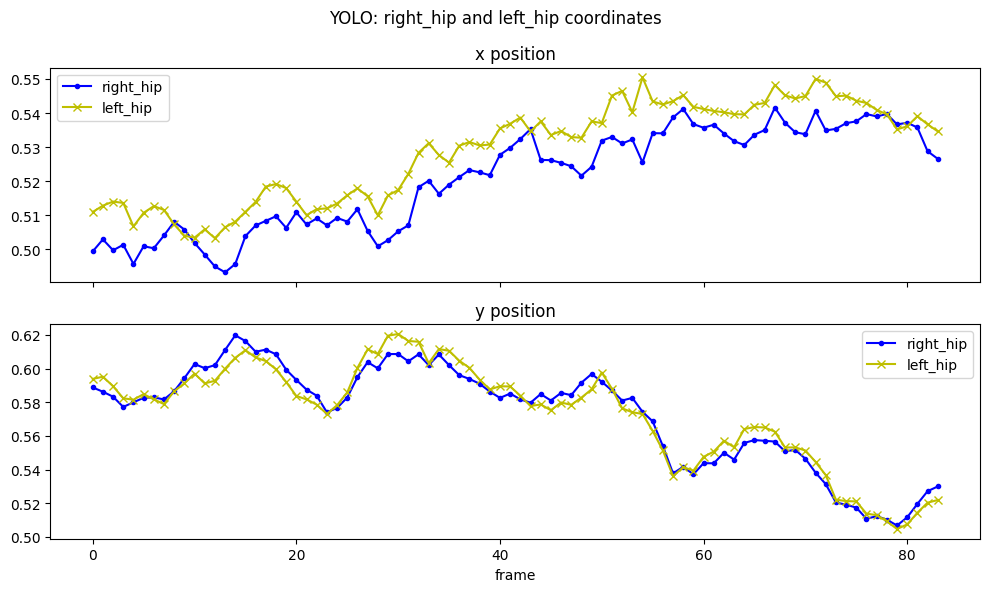

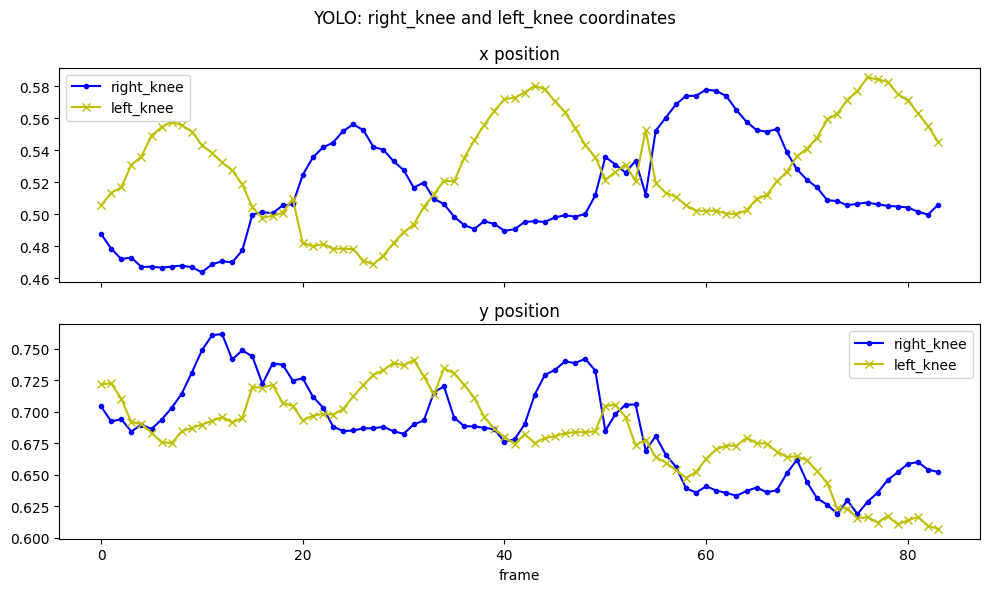

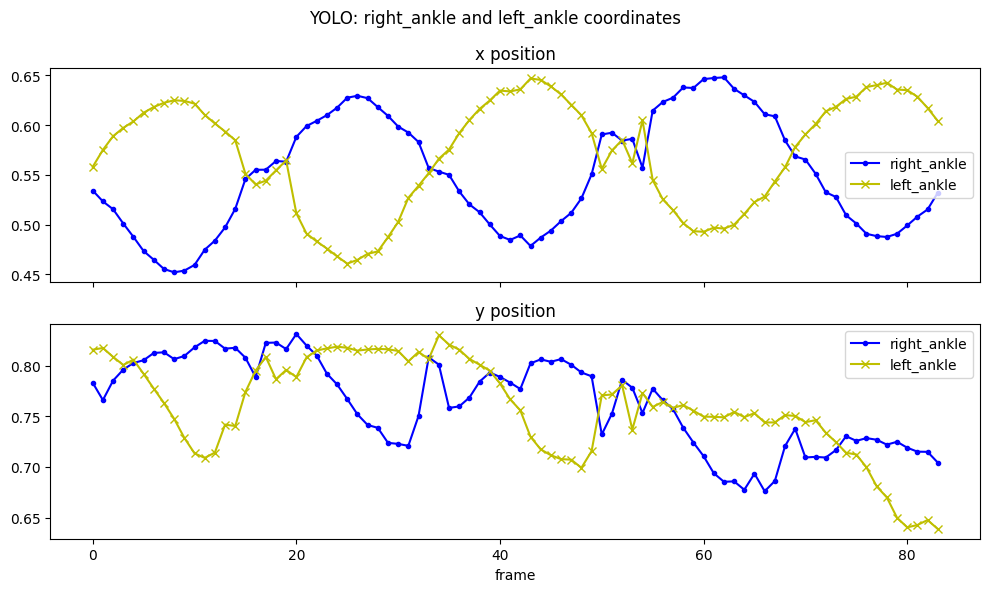

In [23]:
# Load the YOLOv8 model
model = YOLO('yolov8n-pose.pt')

# Open the video file
video_path = "skeleton_tracking/running_2.mp4"
cap = cv2.VideoCapture(video_path)

# NEW:
yolo_positions = []

# Loop through the video frames
while cap.isOpened():
    # Read a frame from the video
    success, frame = cap.read()

    if not success:
        break

    # Run YOLOv8 tracking on the frame, persisting tracks between frames
    results = model.track(frame, persist=True, tracker ='bytetrack.yaml', conf=0.05, classes=0)

    # NEW:
    kpts = results[0].keypoints
    if kpts is not None and len(kpts.xyn) > 0:
        yolo_positions.append(kpts.xyn[0].cpu().numpy())
    else:
        yolo_positions.append(np.full((17, 2), np.nan))

    # Visualize the results on the frame
    annotated_frame = results[0].plot()

    # Display the annotated frame
    cv2.imshow("YOLOv8 Tracking", annotated_frame)

    # Break the loop if 'q' is pressed
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

# Release the video capture object and close windows
cv2.waitKey(0)
cv2.destroyWindow("YOLOv8 Tracking")
cv2.waitKey(1)
cap.release()

# NEW:
yolo_positions = np.array(yolo_positions)
frames = np.arange(len(yolo_positions))

for joint in ['hip', 'knee', 'ankle']:
    r = KEYPOINT_DICT['right_' + joint]
    l = KEYPOINT_DICT['left_' + joint]

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    for row, title in enumerate(['x position', 'y position']):
        axes[row].plot(frames, yolo_positions[:, r, row], 'b.-', label='right_' + joint)
        axes[row].plot(frames, yolo_positions[:, l, row], 'yx-', label='left_' + joint)
        axes[row].set_title(title)
        axes[row].legend()
    axes[1].set_xlabel('frame')
    fig.suptitle(f'YOLO: right_{joint} and left_{joint} coordinates')
    plt.tight_layout()
    plt.show()

# Pose estimation with MoveNet vs YOLO

## Task 5: Compare MoveNet and YOLO

### 5.1. Code assignment

Plot joint coordinates of hip, knee and ankle of right and left sides comparing both models. Plot both models on the same chart, use red for MoveNet and purple for YOLO.

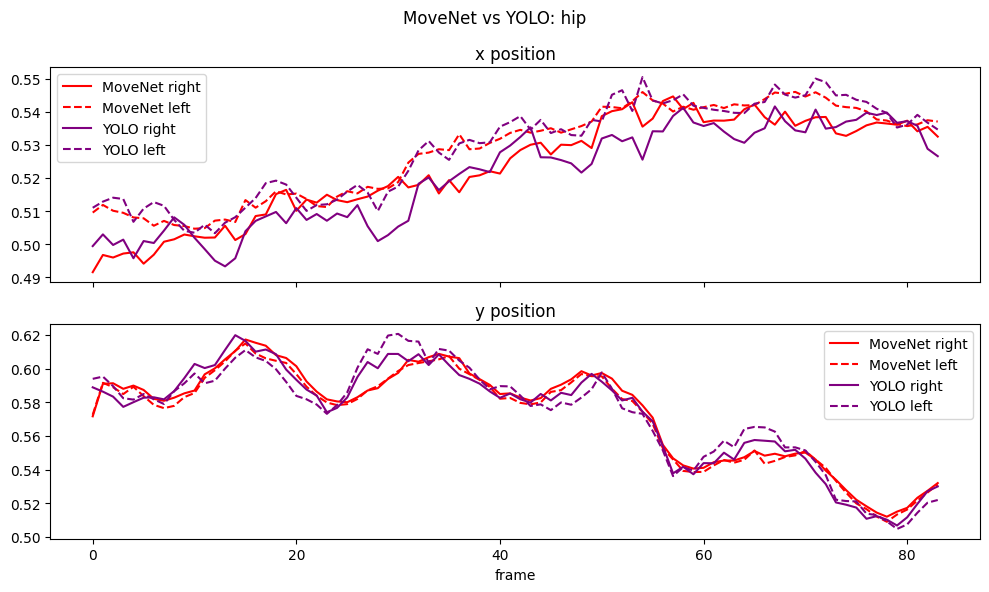

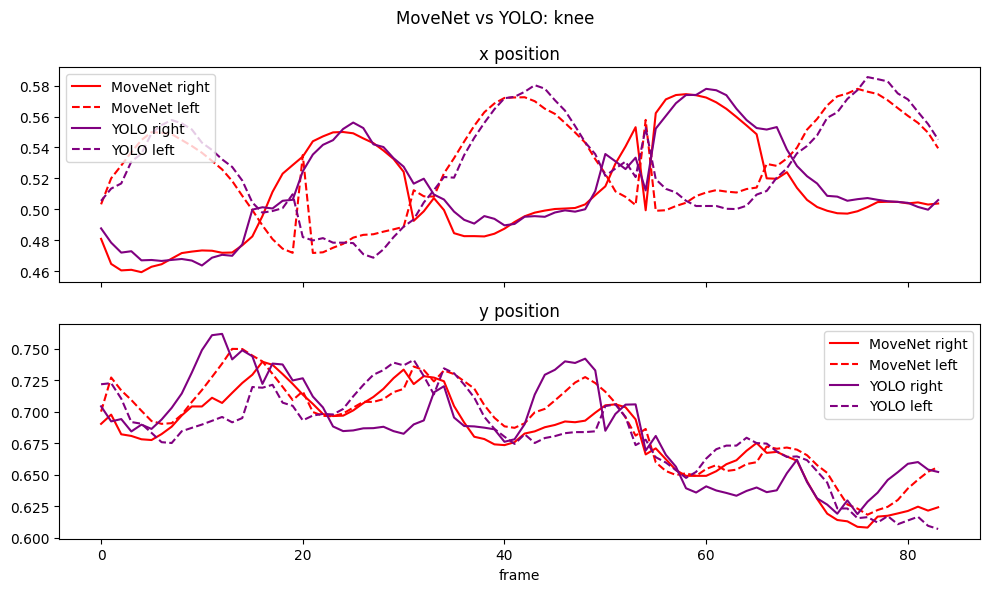

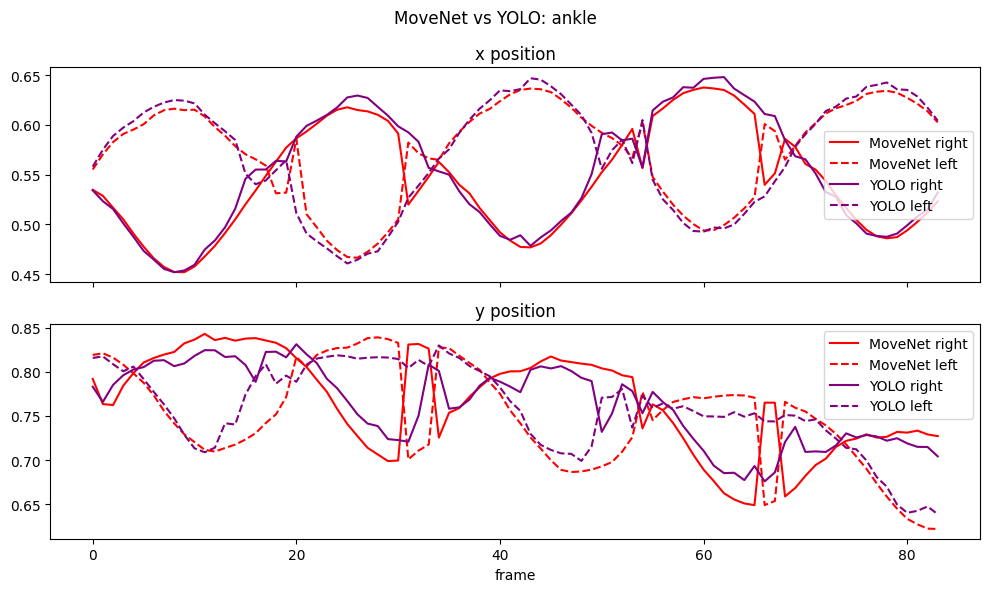

In [24]:
frames = np.arange(len(positions))

for joint in ['hip', 'knee', 'ankle']:
    r = KEYPOINT_DICT['right_' + joint]
    l = KEYPOINT_DICT['left_' + joint]

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    for row, title in enumerate(['x position', 'y position']):
        ax = axes[row]
        ax.plot(frames, positions[:, r, row], 'r-', label='MoveNet right')
        ax.plot(frames, positions[:, l, row], 'r--', label='MoveNet left')
        ax.plot(frames, yolo_positions[:, r, row], '-', color='purple', label='YOLO right')
        ax.plot(frames, yolo_positions[:, l, row], '--', color='purple', label='YOLO left')
        ax.set_title(title)
        ax.legend()
    axes[1].set_xlabel('frame')
    fig.suptitle(f'MoveNet vs YOLO: {joint}')
    plt.tight_layout()
    plt.show()

### 5.2. Written assignment

Analyze and compare the results of both models. Write a paragraph with your reflections.

Both models give similar results overall, especially for the hips, where the curves are almost identical. The main difference is in the knees and ankles. MoveNet has several sudden left/right swaps, while YOLO's curves continue smoothly at those frames, probably because YOLO's tracking keeps the person consistent between frames.
Both models swap the legs which shows that the moment when the legs pass each other is hard for both.YOLOs y coordinates for the knees and ankles are noisier than MoveNets. Neither model is clearly better everywhere. YOLO makes fewer swap errors and MoveNet gives smoother curves when its predictions are correct.

## Bonus task 1

(For you who like sports)

Record YOUR OWN sports-related video, perform the skeleton tracking and compute important angles or other biomechanics variables. Use both models and compare the results of the predictions. Time your code and find which model was faster. Analyse the results and discuss how they would be used in real life.

## Bonus task 2

(For you who like sports and programming)

Think of a method to identify the predictions where the right and left sides swap. Think of a method to improve those predictions and implement it. Describe your method and compare the results with and without your method. (Tips: Use the Kalman Filter implementation on kalmanFilter.py. The Kalman filter provides an estimate of the next prediction. You can use the distance of the model prediction and the Kalman prediction to try and identify side swaps).

Implement your code below and use markdowns to discuss the results.  
Extra tip: if you use a Kalman Filter, you must remember that the side swap has to be fixed before the next iteration.

Example of coordinates plot of the knee joint comparing with and without fixing predictions. Do not consider those values.

![Fixed joint coordinates plot example](example_plots/knee_coordinates_fixed.png)

In [25]:
from kalmanFilter import KalmanFilter